# ESCM 2.0 — Generalization beyond vertical edges

## Research question

Notebook 18 identified a **single selected operating point** on a 9 × 9 general spatial grid that maintained and replaced vertical five-pixel edges. It also failed when two edges were presented simultaneously. Here we keep that configuration **fixed**, and test whether sequential replacement generalizes to *new spatial patterns and event timings*.

This is a **held-out evaluation**, not a new parameter search. No feature is added to the network, and we do not alter its neuronal equations or connectivity. The same homogeneous LIF grid, assignment-based autapses, and distance-based surround inhibition from Notebook 18 are reused directly.

**Fixed parameters:** $\tau_m=10$ ms, $\tau_{ext}=3$ ms, $\tau_E=5$ ms, $\tau_I=12$ ms, threshold 1, self-gain 8, input gain $\beta=22$, surround inhibitory gain $g_I=0.1$, $\sigma_I=2.5$ pixels, inhibitory annulus $1.5<d\le4.5$ pixels, no lateral excitation, $\Delta t=0.05$ ms.

**Claim tested:** for the specified finite set of geometry and timing protocols, the old shape is persistent by itself, the new shape is persistent by itself, and sequential input yields a persistent new shape, silent old shape and no persistent off-target neurons. The notebook does **not** test arbitrary shapes, biological fidelity or real event-camera recordings.

## 1. Define geometries and the unchanged network

A *shape* is simply an array of pixel indices, with $i=yW+x$. We use exactly five pixels per shape so that differences are attributable to geometry, rather than representation size. All shapes are placed within the original 9 × 9 field.

The tests include vertical (the reference geometry), horizontal, diagonal, L-shaped, and stepped shapes. Each pair has no shared pixels; neither shape's identity is used to construct recurrent synapses.

An input consists of three events per target neuron. The first shape receives events at 2, 4 and 6 ms, while the second receives events after a controlled delay.

/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


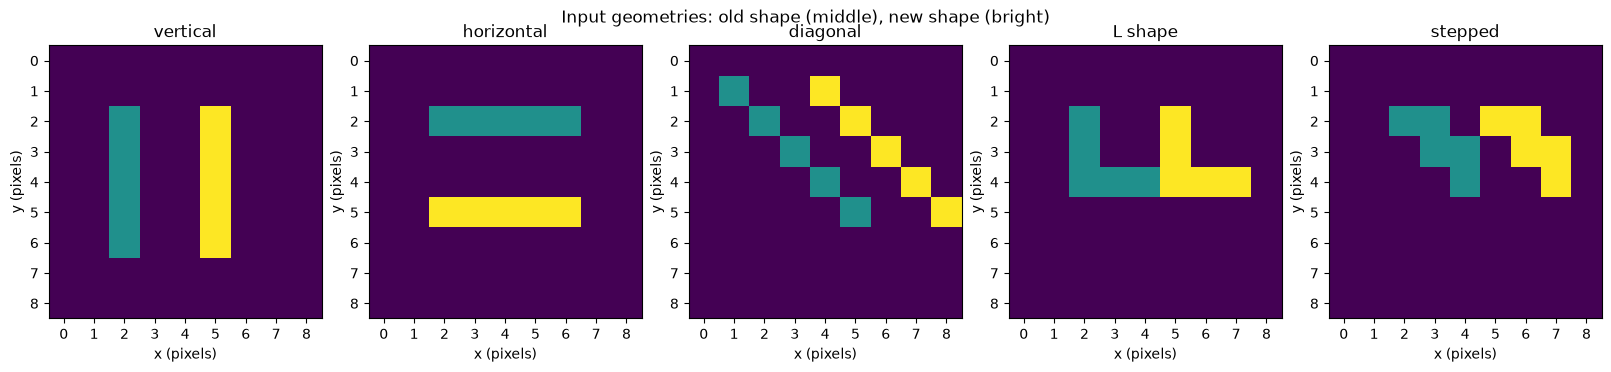

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import brian2 as b2

b2.prefs.codegen.target = "numpy"
width = height = 9
n = width * height
xy = np.column_stack(np.unravel_index(np.arange(n), (height, width)))[..., ::-1]
tm, tx, te, ti = 10., 3., 5., 12.  # ms
self_weight, threshold = 8., 1.
sigma_e, sigma_i = 0.9, 2.5
radius_e, radius_i = 1.5, 4.5

def pixels(coordinates):
    return np.array([y*width+x for x, y in coordinates], dtype=int)

shapes = {
    "vertical": (
        pixels([(2, y) for y in range(2, 7)]),
        pixels([(5, y) for y in range(2, 7)])),
    "horizontal": (
        pixels([(x, 2) for x in range(2, 7)]),
        pixels([(x, 5) for x in range(2, 7)])),
    "diagonal": (
        pixels([(x, x) for x in range(1, 6)]),
        pixels([(x+3, x) for x in range(1, 6)])),
    "L shape": (
        pixels([(2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]),
        pixels([(5, 2), (5, 3), (5, 4), (6, 4), (7, 4)])),
    "stepped": (
        pixels([(2, 2), (3, 2), (3, 3), (4, 3), (4, 4)]),
        pixels([(5, 2), (6, 2), (6, 3), (7, 3), (7, 4)])),
}
for name, (old, new) in shapes.items():
    assert len(old) == len(new) == 5
    assert len(set(old) | set(new)) == 10
    assert all(0 <= p < n for p in np.r_[old, new]), name

fig, axes = plt.subplots(1, len(shapes), figsize=(16, 3.5), constrained_layout=True)
for ax, (name, (old, new)) in zip(axes, shapes.items()):
    im = np.zeros((height, width), dtype=int)
    im.flat[old], im.flat[new] = 1, 2
    ax.imshow(im, cmap="viridis", vmin=0, vmax=2)
    ax.set(title=name, xlabel="x (pixels)", ylabel="y (pixels)",
           xticks=range(width), yticks=range(height))
fig.suptitle("Input geometries: old shape (middle), new shape (bright)")
plt.show()

## 2. Simulate the unchanged ESCM 2.0 network

These equations and spatial weights are copied from Notebook 18. Each external event adds $22$ to the corresponding neuron's $I_{ext}$. Each output spike refreshes its own $I_E$ to 8. For spatial neighbors inside the inhibitory annulus, presynaptic spikes add $g_I\exp[-d_{ij}^2/(2\sigma_I^2)]$ to the postsynaptic inhibitory state.

The sole implementation change is that `simulate()` accepts an external event schedule, so it can run arbitrary shapes **without changing recurrent connectivity**. The synaptic graph is constructed only from spatial distances.

In [2]:
def simulate(schedule, beta=22., g_i=0.1, g_e=0., surround=True, dt=0.05):
    b2.start_scope()
    b2.defaultclock.dt = dt * b2.ms

    # Each schedule entry is (pixel_ids, pulse_times_ms, row_delay_ms).
    # The recurrent graph below never depends on these pixel identities.
    ids, times = [], []
    for pixels, pulses, row_delay in schedule:
        for pulse in pulses:
            for j, pixel in enumerate(pixels):
                ids.append(int(pixel))
                times.append(pulse + j * row_delay)
    order = np.argsort(times, kind="stable")
    camera = b2.SpikeGeneratorGroup(
        n, np.asarray(ids, dtype=int)[order],
        np.asarray(times, dtype=float)[order] * b2.ms)

    parameters = dict(tau_m=tm*b2.ms, tau_ext=tx*b2.ms,
                      tau_exc=te*b2.ms, tau_inh=ti*b2.ms,
                      v_threshold=threshold, self_gain=self_weight,
                      camera_gain=beta)
    neurons = b2.NeuronGroup(n, """
        dv/dt = (-v + Iext + Iexc - Iinh)/tau_m : 1
        dIext/dt = -Iext/tau_ext : 1
        dIexc/dt = -Iexc/tau_exc : 1
        dIinh/dt = -Iinh/tau_inh : 1
    """, threshold="v > v_threshold", reset="v = 0",
        method="exact", namespace=parameters)
    neurons.v = neurons.Iext = neurons.Iexc = neurons.Iinh = 0

    feed = b2.Synapses(camera, neurons, on_pre="Iext_post += camera_gain",
                       namespace=parameters)
    feed.connect(j="i")
    autapse = b2.Synapses(neurons, neurons,
                          on_pre="Iexc_post = self_gain", namespace=parameters)
    autapse.connect(i=np.arange(n), j=np.arange(n))
    objects = [camera, neurons, feed, autapse]

    distances = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=-1)
    # distances[post, pre], so the row is the postsynaptic cell.
    if g_i > 0:
        min_radius = 1.5 if surround else 0.
        post, pre = np.where((distances > min_radius) &
                             (distances <= radius_i))
        weights = g_i * np.exp(-distances[post, pre]**2/(2*sigma_i**2))
        lateral_inh = b2.Synapses(neurons, neurons, "w : 1",
                                 on_pre="Iinh_post += w")
        lateral_inh.connect(i=pre, j=post)
        lateral_inh.w = weights
        objects.append(lateral_inh)
    if g_e > 0:
        post, pre = np.where((distances > 0) & (distances <= radius_e))
        weights = g_e * np.exp(-distances[post, pre]**2/(2*sigma_e**2))
        lateral_exc = b2.Synapses(neurons, neurons, "w : 1",
                                 on_pre="Iexc_post += w")
        lateral_exc.connect(i=pre, j=post)
        lateral_exc.w = weights
        objects.append(lateral_exc)

    spike_monitor = b2.SpikeMonitor(neurons)
    objects.append(spike_monitor)
    b2.Network(*objects).run(130*b2.ms)
    return dict(t=np.asarray(spike_monitor.t/b2.ms),
                i=np.asarray(spike_monitor.i, dtype=int))


## 3. Replacement requires matched persistence controls

A new shape being active after the second input does **not** establish replacement. We must separately verify that the old shape persists without a replacement stimulus; otherwise the old activity could have simply faded.

The success criterion is deliberately the same as Notebook 18: in both independent late windows **[90,105) and [105,120) ms**, each old or new pixel must emit at least two spikes in its corresponding solo run. After sequential stimulation, old pixels must emit zero spikes in both windows, new pixels must emit at least two spikes in both, and all other pixels must remain silent.

This is a strict finite-window test of sustained activity. It does not claim persistence for infinite time.

In [3]:
def evaluate(old, new, second_start=40., row_delay=0., dt=0.05):
    pulse_old = (2., 4., 6.)
    pulse_new = (second_start, second_start+2, second_start+4)
    old_input = (old, pulse_old, row_delay)
    new_input = (new, pulse_new, row_delay)
    old_run = simulate([old_input], dt=dt)
    new_run = simulate([new_input], dt=dt)
    replacement = simulate([old_input, new_input], dt=dt)
    windows = ((90., 105.), (105., 120.))
    def per_pixel(run, indices):
        return np.array([[np.count_nonzero((run["i"] == pixel) &
                   (run["t"] >= left) & (run["t"] < right))
                   for pixel in indices] for left, right in windows])
    old_ctrl = per_pixel(old_run, old)
    new_ctrl = per_pixel(new_run, new)
    old_after = per_pixel(replacement, old)
    new_after = per_pixel(replacement, new)
    background = np.setdiff1d(np.arange(n), np.r_[old, new])
    other = per_pixel(replacement, background)
    stable_old = (old_ctrl >= 2).all(axis=0)
    stable_new = (new_ctrl >= 2).all(axis=0)
    removed_old = (old_after == 0).all(axis=0)
    stable_new_after = (new_after >= 2).all(axis=0)
    quiet = (other == 0).all(axis=0)
    return dict(old_control=int(stable_old.sum()), new_control=int(stable_new.sum()),
                old_silent=int(removed_old.sum()), new_persistent=int(stable_new_after.sum()),
                off_target=int((~quiet).sum()),
                success=bool(stable_old.all() and stable_new.all() and
                             removed_old.all() and stable_new_after.all() and quiet.all()))

geometry_results = []
for name, (old, new) in tqdm(shapes.items(), total=len(shapes), desc="Held-out geometry"):
    geometry_results.append(dict(geometry=name, **evaluate(old, new)))
geometry_table = pd.DataFrame(geometry_results)
display(geometry_table)
print(f"Strictly successful geometries: {geometry_table.success.sum()}/{len(geometry_table)}")

Held-out geometry: 100%|██████████| 5/5 [00:05<00:00,  1.05s/it]


,geometry,old_control,new_control,old_silent,new_persistent,off_target,success
0,vertical,5,5,5,5,0,True
1,horizontal,5,5,5,5,0,True
2,diagonal,5,5,3,5,0,False
3,L shape,5,5,4,5,0,False
4,stepped,5,5,4,5,0,False


Strictly successful geometries: 2/5


## 4. Timing robustness without retuning the network

The original asynchronous protocol staggered five pixel inputs by 0.25 ms per successive pixel. We now test row-to-row delays of 0, 0.25, 0.5, and 1 ms. We also move the second stimulus to different times while keeping the first fixed at 2–6 ms.

The late evaluation window remains unchanged. This makes the short-delay and long-delay conditions directly comparable, but later second inputs have less time to establish sustained activity. That is part of the challenge being tested.

These are controlled, deterministic timing patterns, **not random event-camera statistics**.

Input onset time: 100%|██████████| 4/4 [00:11<00:00,  2.85s/it]


,second_start_ms,row_delay_ms,old_control,new_control,old_silent,new_persistent,off_target,success
0,20.0,0.00,5,5,5,5,0,True
1,20.0,0.25,5,5,5,5,0,True
2,20.0,0.50,5,5,5,5,0,True
3,20.0,1.00,5,5,5,5,0,True
4,40.0,0.00,5,5,5,5,0,True
5,40.0,0.25,5,5,5,5,0,True
6,40.0,0.50,5,5,5,5,0,True
7,40.0,1.00,5,5,5,5,0,True
8,60.0,0.00,5,5,5,5,0,True
9,60.0,0.25,5,5,5,5,0,True


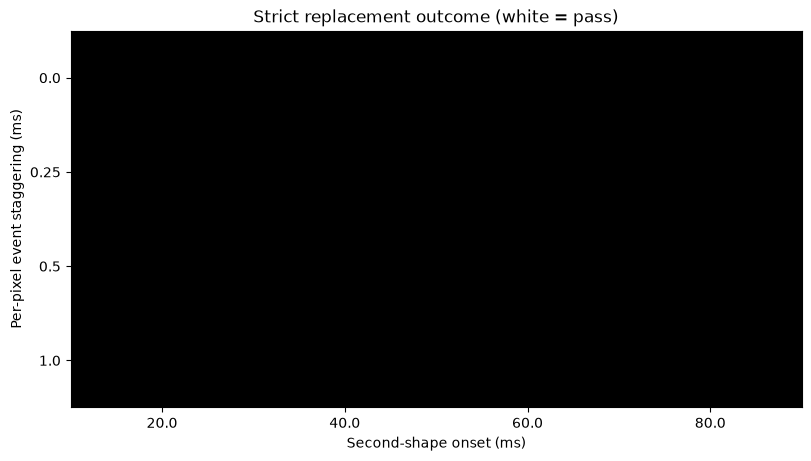

In [4]:
timing_results = []
old, new = shapes["vertical"]
for second_start in tqdm((20., 40., 60., 80.), desc="Input onset time"):
    for row_delay in (0., 0.25, 0.5, 1.):
        timing_results.append(dict(second_start_ms=second_start,
                                   row_delay_ms=row_delay,
                                   **evaluate(old, new,
                                              second_start=second_start,
                                              row_delay=row_delay)))
timing_table = pd.DataFrame(timing_results)
display(timing_table)
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
success_map = timing_table.pivot(index="row_delay_ms", columns="second_start_ms", values="success")
ax.imshow(success_map.to_numpy(dtype=float), cmap="Greys", vmin=0, vmax=1,
          aspect="auto", interpolation="nearest")
ax.set(xticks=range(len(success_map.columns)), xticklabels=success_map.columns,
       yticks=range(len(success_map.index)), yticklabels=success_map.index,
       xlabel="Second-shape onset (ms)", ylabel="Per-pixel event staggering (ms)",
       title="Strict replacement outcome (white = pass)")
plt.show()

## 5. Inspect failure patterns rather than hiding them in a success flag

For every geometry, show the **whole 9 × 9 grid** of late output spikes after replacement. These maps reveal partial survival, spurious excitation and coexistence that a binary success metric cannot distinguish.

All maps use identical color scaling so that their spike counts can be compared. The shapes appear only in the stimulus and the display; connectivity remains unlabelled.

Spatial activity maps: 100%|██████████| 5/5 [00:01<00:00,  4.08it/s]


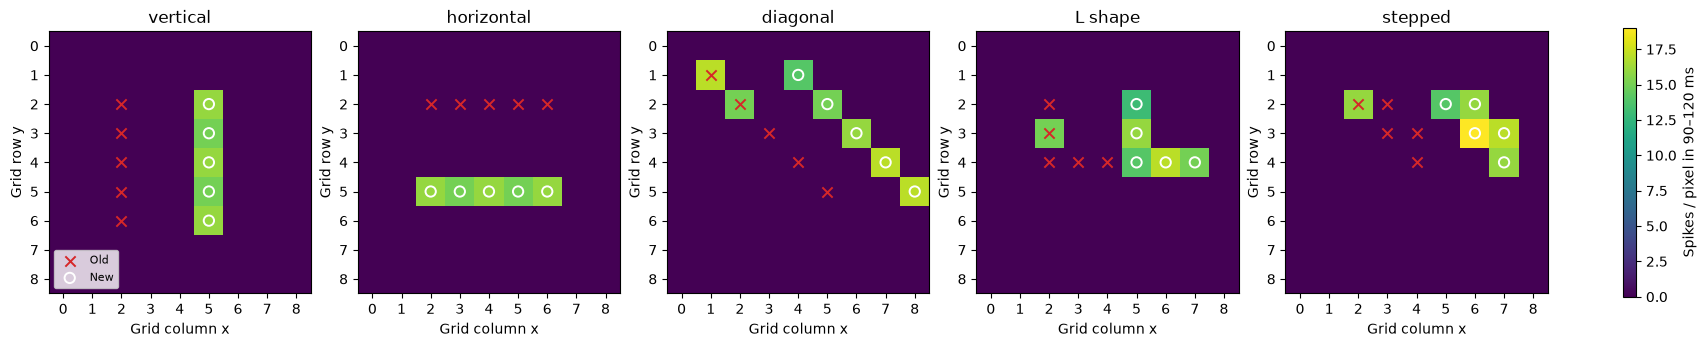

In [5]:
maps = []
for name, (old, new) in tqdm(shapes.items(), total=len(shapes), desc="Spatial activity maps"):
    r = simulate([(old, (2., 4., 6.), 0.), (new, (40., 42., 44.), 0.)])
    late = r["i"][(r["t"] >= 90) & (r["t"] < 120)]
    maps.append(np.bincount(late, minlength=n).reshape(height, width))

fig, axes = plt.subplots(1, len(shapes), figsize=(17, 3.7), constrained_layout=True)
max_count = max(int(x.max()) for x in maps)
for ax, (name, (old, new)), activity in zip(axes, shapes.items(), maps):
    im = ax.imshow(activity, origin="upper", cmap="viridis",
                   vmin=0, vmax=max(max_count, 1))
    ax.scatter(xy[old, 0], xy[old, 1], marker="x", s=55,
               color="tab:red", linewidth=1.4, label="Old")
    ax.scatter(xy[new, 0], xy[new, 1], marker="o", s=55,
               facecolors="none", edgecolors="white", linewidth=1.4, label="New")
    ax.set(title=name, xlabel="Grid column x", ylabel="Grid row y",
           xticks=range(width), yticks=range(height))
axes[0].legend(loc="lower left", fontsize=8)
fig.colorbar(im, ax=axes, label="Spikes / pixel in 90–120 ms", shrink=0.75)
plt.show()

## 6. Numerical resolution control

Repeat the original successful vertical geometry and any new geometry that passes, at $\Delta t=0.1,0.05,0.025$ ms. We report the **finite-window replacement outcome**, not full spike-time equivalence. Failed geometries are not silently removed from the table: they remain visible in the main results.

If the model works only for the original orientation or event timing, the appropriate next step is to analyze its **spatial inhibition geometry** before modifying the circuit.

In [6]:
refinement = []
controls = ["vertical"] + [name for name, row in geometry_table.set_index("geometry").iterrows()
                            if row.success and name != "vertical"]
for name in tqdm(controls, desc="Timestep verification"):
    old, new = shapes[name]
    for dt in (0.1, 0.05, 0.025):
        refinement.append(dict(geometry=name, dt_ms=dt,
                               **evaluate(old, new, dt=dt)))
display(pd.DataFrame(refinement))
print("Completed. Interpret the full geometry and timing tables before changing model parameters.")

Timestep verification: 100%|██████████| 2/2 [00:04<00:00,  2.38s/it]


,geometry,dt_ms,old_control,new_control,old_silent,new_persistent,off_target,success
0,vertical,0.100,5,5,5,5,0,True
1,vertical,0.050,5,5,5,5,0,True
2,vertical,0.025,5,5,5,5,0,True
3,horizontal,0.100,5,5,5,5,0,True
4,horizontal,0.050,5,5,5,5,0,True
5,horizontal,0.025,5,5,5,5,0,True


Completed. Interpret the full geometry and timing tables before changing model parameters.


## Interpretation and limits

**Supported only if the corresponding tables pass:** (i) each shape persists in its solo control, (ii) sequential input suppresses old activity and sustains the new shape, (iii) no unrelated neurons become persistently active, and (iv) these classifications are robust to tested event timing and timestep variations.

**Not claimed:** convergence of individual spike times, indefinite persistence, biological correctness of current assignment, arbitrary-shape generalization, or accuracy on real event-camera recordings. Simultaneous multi-edge preservation was already a failure in Notebook 18 and is not treated as solved here.

**Next decision:** if geometry and timing generalization are adequate, progress to moving objects and real event streams; otherwise use the observed spatial failure modes to revise *one* neural interaction at a time.